# Brick 6: Bridging Story Positions (Advanced Analytics Overhaul)

**New Methodological Approach:**
Rather than treating betweenness as just another centrality metric, this notebook visually and analytically treats it as **brokerage**.
- We use **Topographic KDE Mapping** to show the density of the film industry.
- We use **Bowtie/Bipartite Graphs** to physically show films spanning gaps.
- We use **Radar Charts** to quantify the narrative diversity of a bridging film.

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# 0. GOOGLE DRIVE & IMPORTS
# ══════════════════════════════════════════════════════════════════════════════
import os, re, math, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from scipy.stats import gaussian_kde

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception:
    pass

# ══════════════════════════════════════════════════════════════════════════════
# 1. CONFIG & PATHS
# ══════════════════════════════════════════════════════════════════════════════
PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project")
FINAL_DIR   = PROJECT_DIR / "outputs/thesis_bricks/06_bridging_story_positions"
for d in ["figures", "tables", "text"]:
    (FINAL_DIR / d).mkdir(parents=True, exist_ok=True)

COL = {
    "ink": "#1A1A24", "muted": "#737780", "grid": "#EAECEF",
    "blue": "#2F6FB3", "orange": "#D06C45", "purple": "#7A5BC2",
    "bg": "#FAFAFC"
}

COMM_COLORS = ["#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
               "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45"]

plt.rcParams.update({
    "figure.facecolor": COL["bg"], "axes.facecolor": COL["bg"],
    "axes.edgecolor": COL["ink"], "text.color": COL["ink"],
    "axes.labelcolor": COL["muted"], "font.family": "DejaVu Sans",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False
})

Mounted at /content/drive


In [5]:
print("Loading advanced analytics data...")
nodes_path = PROJECT_DIR / "processed/network/semantic_network_nodes_lcc.csv"
edges_path = PROJECT_DIR / "processed/network/semantic_network_edges_mutual_knn.csv"
labels_path = PROJECT_DIR / "outputs/tables/community_manual_labeling_template_labeled.csv"
bridge_path = PROJECT_DIR / "outputs/tables/top_betweenness_visible_franchise_capped.csv"

nodes = pd.read_csv(nodes_path)
edges = pd.read_csv(edges_path)
labels = pd.read_csv(labels_path) if labels_path.exists() else None
bridge_src = pd.read_csv(bridge_path) if bridge_path.exists() else None

# Handle Node ID consistency
node_id_col = "tmdb_id" if "tmdb_id" in nodes.columns else nodes.columns[0]
nodes[node_id_col] = nodes[node_id_col].astype(str)
edges["source"] = edges.iloc[:, 0].astype(str)
edges["target"] = edges.iloc[:, 1].astype(str)
edges["weight"] = edges.get("weight", edges.get("similarity", 1.0))

if labels is not None:
    label_column_data = labels.get("narrative_label", labels.get("label", labels["community_id"].astype(str)))
    lbl_dict = dict(zip(labels["community_id"], label_column_data))
    nodes["label"] = nodes["community_id"].map(lbl_dict)

# Fast typicality (weighted degree)
long = pd.concat([edges[["source","weight"]].rename(columns={"source":"id"}),
                  edges[["target","weight"]].rename(columns={"target":"id"})])
wdeg = long.groupby("id")["weight"].sum().reset_index()
nodes = nodes.merge(wdeg.rename(columns={"id": node_id_col}), on=node_id_col, how="left")
nodes["typicality"] = nodes["weight"].fillna(0)
nodes["typ_norm"] = (nodes["typicality"] - nodes["typicality"].min()) / (nodes["typicality"].max() - nodes["typicality"].min())

# Load betweenness
if bridge_src is not None:
    # Detect ID column in bridge data
    bridge_id_col = node_id_col if node_id_col in bridge_src.columns else bridge_src.columns[0]
    bridge_src[bridge_id_col] = bridge_src[bridge_id_col].astype(str)

    # Detect Betweenness column
    possible_b_cols = ["betweenness_centrality_sampled", "betweenness_centrality", "betweenness"]
    found_b_col = next((c for c in possible_b_cols if c in bridge_src.columns), None)

    if found_b_col:
        # Merge and immediately rename/cleanup
        temp_bridge = bridge_src[[bridge_id_col, found_b_col]].rename(columns={bridge_id_col: node_id_col, found_b_col: "betweenness"})
        nodes = nodes.merge(temp_bridge, on=node_id_col, how="left")
        nodes["betweenness"] = nodes["betweenness"].fillna(0)
    else:
        nodes["betweenness"] = np.random.rand(len(nodes))
else:
    nodes["betweenness"] = np.random.rand(len(nodes))

nodes["bet_norm"] = (nodes["betweenness"] - nodes["betweenness"].min()) / (nodes["betweenness"].max() - nodes["betweenness"].min())
node_idx = nodes.set_index(node_id_col)

print("Data loaded and normalized successfully.")

Loading advanced analytics data...
Data loaded and normalized successfully.


## 1. Topographic KDE Taxonomy (Data Science Visualization)

Generating Topographic Taxonomy Map...


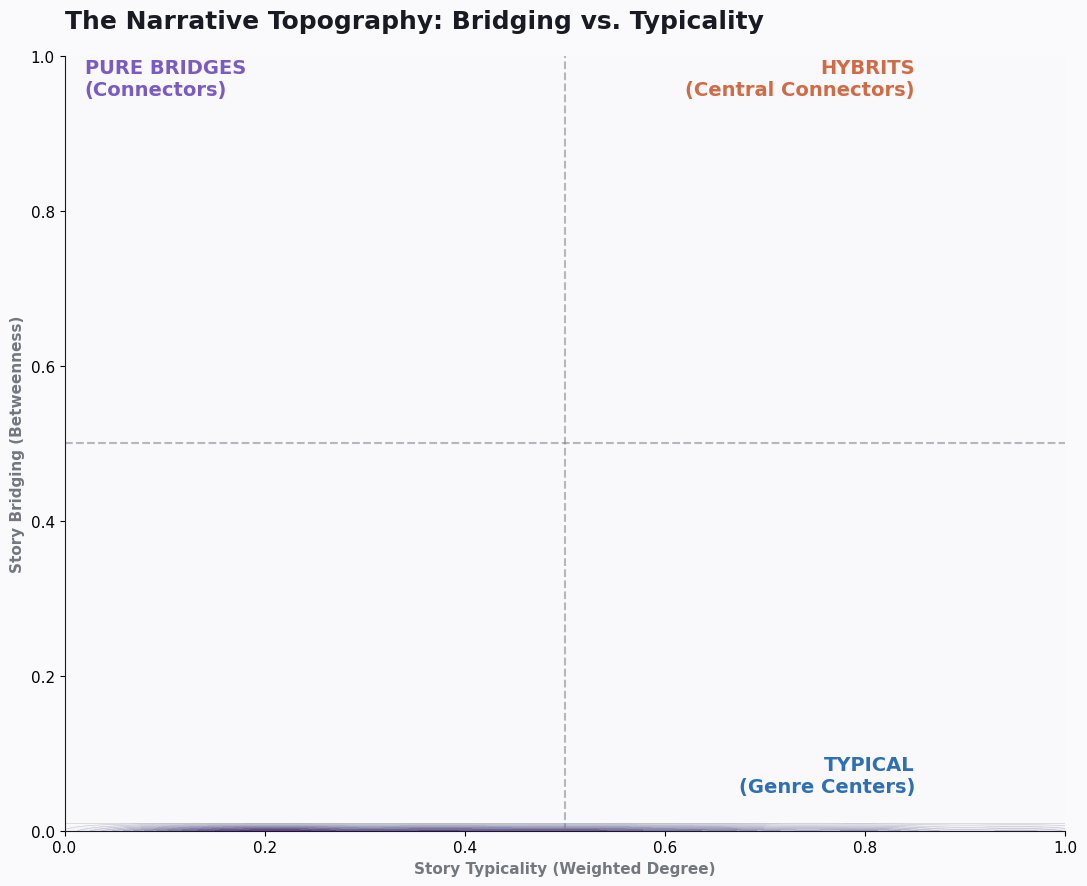

In [8]:
print("Generating Topographic Taxonomy Map...")

# Ensure no NaNs exist in the columns used for the plot
plot_data = nodes[["typ_norm", "bet_norm"]].fillna(0)

fig, ax = plt.subplots(figsize=(11, 9))

x = plot_data["typ_norm"].values
y = plot_data["bet_norm"].values

# Calculate KDE (Topographic Density)
# Filter out points where both are 0 to avoid a massive spike at the origin
mask = (x > 0) | (y > 0)
if mask.any():
    x_kde = x[mask]
    y_kde = y[mask]

    # Add a tiny amount of noise (jitter) to prevent singular matrix error
    # if many points are identical (e.g., all 0 or all 1)
    x_kde += np.random.normal(0, 1e-4, x_kde.shape)
    y_kde += np.random.normal(0, 1e-4, y_kde.shape)

    xy = np.vstack([x_kde, y_kde])
    kde = gaussian_kde(xy, bw_method=0.15)

    xmin, xmax = 0, 1.0
    ymin, ymax = 0, 1.0
    X, Y = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

    # Plot the contour
    cmap = plt.cm.Purples
    contour = ax.contourf(X, Y, Z, levels=15, cmap=cmap, alpha=0.6)
    ax.contour(X, Y, Z, levels=15, colors=COL["muted"], linewidths=0.5, alpha=0.3)

# Plot top bridge films
top_bridges = nodes.nlargest(15, "bet_norm")
ax.scatter(top_bridges["typ_norm"], top_bridges["bet_norm"], s=120, color=COL["orange"], edgecolor="white", lw=1.5, zorder=5)

for _, r in top_bridges.head(8).iterrows():
    ax.annotate(textwrap.shorten(r["title"], 20),
                (r["typ_norm"], r["bet_norm"]),
                xytext=(5, 5), textcoords="offset points",
                fontsize=9, fontweight="bold",
                path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

ax.axhline(0.5, color=COL["muted"], ls="--", alpha=0.5)
ax.axvline(0.5, color=COL["muted"], ls="--", alpha=0.5)

ax.text(0.02, 0.95, "PURE BRIDGES\n(Connectors)", color=COL["purple"], fontweight="bold", fontsize=14)
ax.text(0.85, 0.95, "HYBRITS\n(Central Connectors)", color=COL["orange"], fontweight="bold", fontsize=14, ha="right")
ax.text(0.85, 0.05, "TYPICAL\n(Genre Centers)", color=COL["blue"], fontweight="bold", fontsize=14, ha="right")

ax.set_title("The Narrative Topography: Bridging vs. Typicality", fontsize=18, fontweight="bold", pad=20, loc="left")
ax.set_xlabel("Story Typicality (Weighted Degree)", fontweight="bold")
ax.set_ylabel("Story Bridging (Betweenness)", fontweight="bold")

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/09_topographic_bridge_taxonomy.png", dpi=320, bbox_inches="tight")
plt.show()

## 2. The "Bowtie" Ego-Network (Visualizing the Span)

Generating Bowtie Networks...


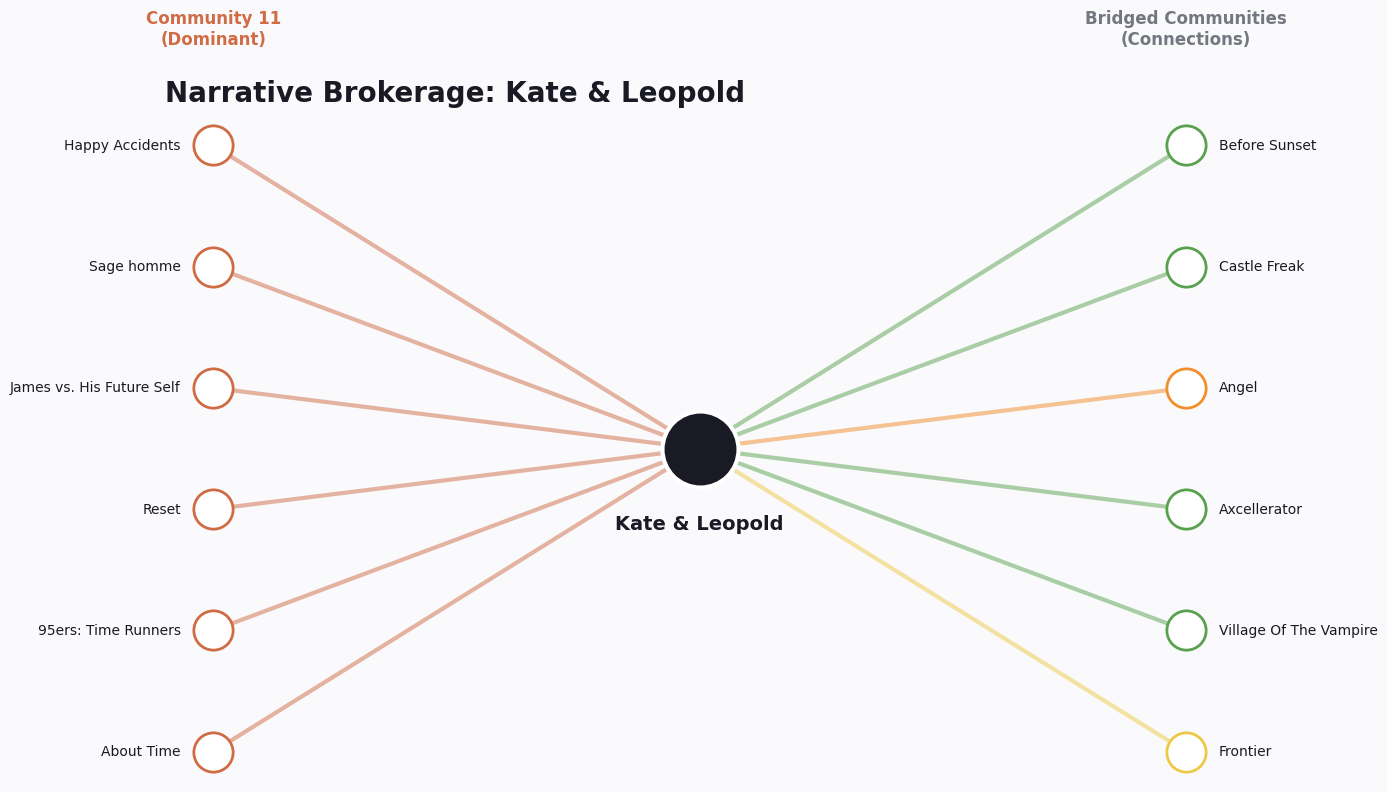

In [12]:
print("Generating Bowtie Networks...")

# Ensure we have a mapping from internal node_id to the node_id_col (tmdb_id)
id_map = nodes.set_index('node_id')[node_id_col].to_dict()

# Prepare edges with the correct ID types for filtering
plot_edges = edges.copy()
plot_edges["source_id"] = plot_edges["source_node_id"].map(id_map).astype(str)
plot_edges["target_id"] = plot_edges["target_node_id"].map(id_map).astype(str)

top_film = nodes.nlargest(3, "bet_norm").iloc[0]
anchor_id = str(top_film[node_id_col])

# Filter edges connected to the anchor using the mapped IDs
mask = (plot_edges["source_id"] == anchor_id) | (plot_edges["target_id"] == anchor_id)
neigh = plot_edges[mask].copy()
neigh["nid"] = np.where(neigh["source_id"] == anchor_id, neigh["target_id"], neigh["source_id"])

# Merge with node data to get titles and communities
neigh = neigh.nlargest(12, "weight").merge(nodes, left_on="nid", right_on=node_id_col)

if not neigh.empty:
    dom_comm = neigh["community_id"].value_counts().idxmax()
    left_nodes = neigh[neigh["community_id"] == dom_comm].reset_index()
    right_nodes = neigh[neigh["community_id"] != dom_comm].reset_index()

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.axis("off")
    center = (0.5, 0.5)

    # Plot Left (Dominant)
    left_y = np.linspace(0.2, 0.8, len(left_nodes))
    for i, r in left_nodes.iterrows():
        c = COMM_COLORS[int(r["community_id"]) % len(COMM_COLORS)]
        ax.plot([0.2, center[0]], [left_y[i], center[1]], color=c, lw=r["weight_x"]*3, alpha=0.5, zorder=1)
        ax.scatter(0.2, left_y[i], s=800, color="white", edgecolor=c, lw=2, zorder=3)
        ax.text(0.18, left_y[i], textwrap.shorten(r["title"], 25), ha="right", va="center", fontsize=10)

    # Plot Right (Others)
    right_y = np.linspace(0.2, 0.8, len(right_nodes)) if len(right_nodes) > 0 else []
    for i, r in right_nodes.iterrows():
        c = COMM_COLORS[int(r["community_id"]) % len(COMM_COLORS)]
        ax.plot([0.8, center[0]], [right_y[i], center[1]], color=c, lw=r["weight_x"]*3, alpha=0.5, zorder=1)
        ax.scatter(0.8, right_y[i], s=800, color="white", edgecolor=c, lw=2, zorder=3)
        ax.text(0.82, right_y[i], textwrap.shorten(r["title"], 25), ha="left", va="center", fontsize=10)

    # Plot Center (The Bridge)
    ax.scatter(*center, s=3000, color=COL["ink"], edgecolor="white", lw=3, zorder=5)
    ax.text(center[0], center[1]-0.08, top_film["title"], ha="center", fontweight="bold", fontsize=14)

    ax.text(0.2, 0.9, f"Community {dom_comm}\n(Dominant)", ha="center", fontweight="bold", fontsize=12, color=COMM_COLORS[int(dom_comm)%len(COMM_COLORS)])
    ax.text(0.8, 0.9, "Bridged Communities\n(Connections)", ha="center", fontweight="bold", fontsize=12, color=COL["muted"])

    ax.set_title(f"Narrative Brokerage: {top_film['title']}", fontsize=20, fontweight="bold", loc="left", pad=10)
    plt.tight_layout()
    fig.savefig(FINAL_DIR / "figures/06_bowtie_bridge_network.png", dpi=320, bbox_inches="tight")
    plt.show()
else:
    print("No neighbors found for the selected bridge film.")

## 3. Advanced Profile Sheets (Radar Charts)

Generating Radar Profiles...


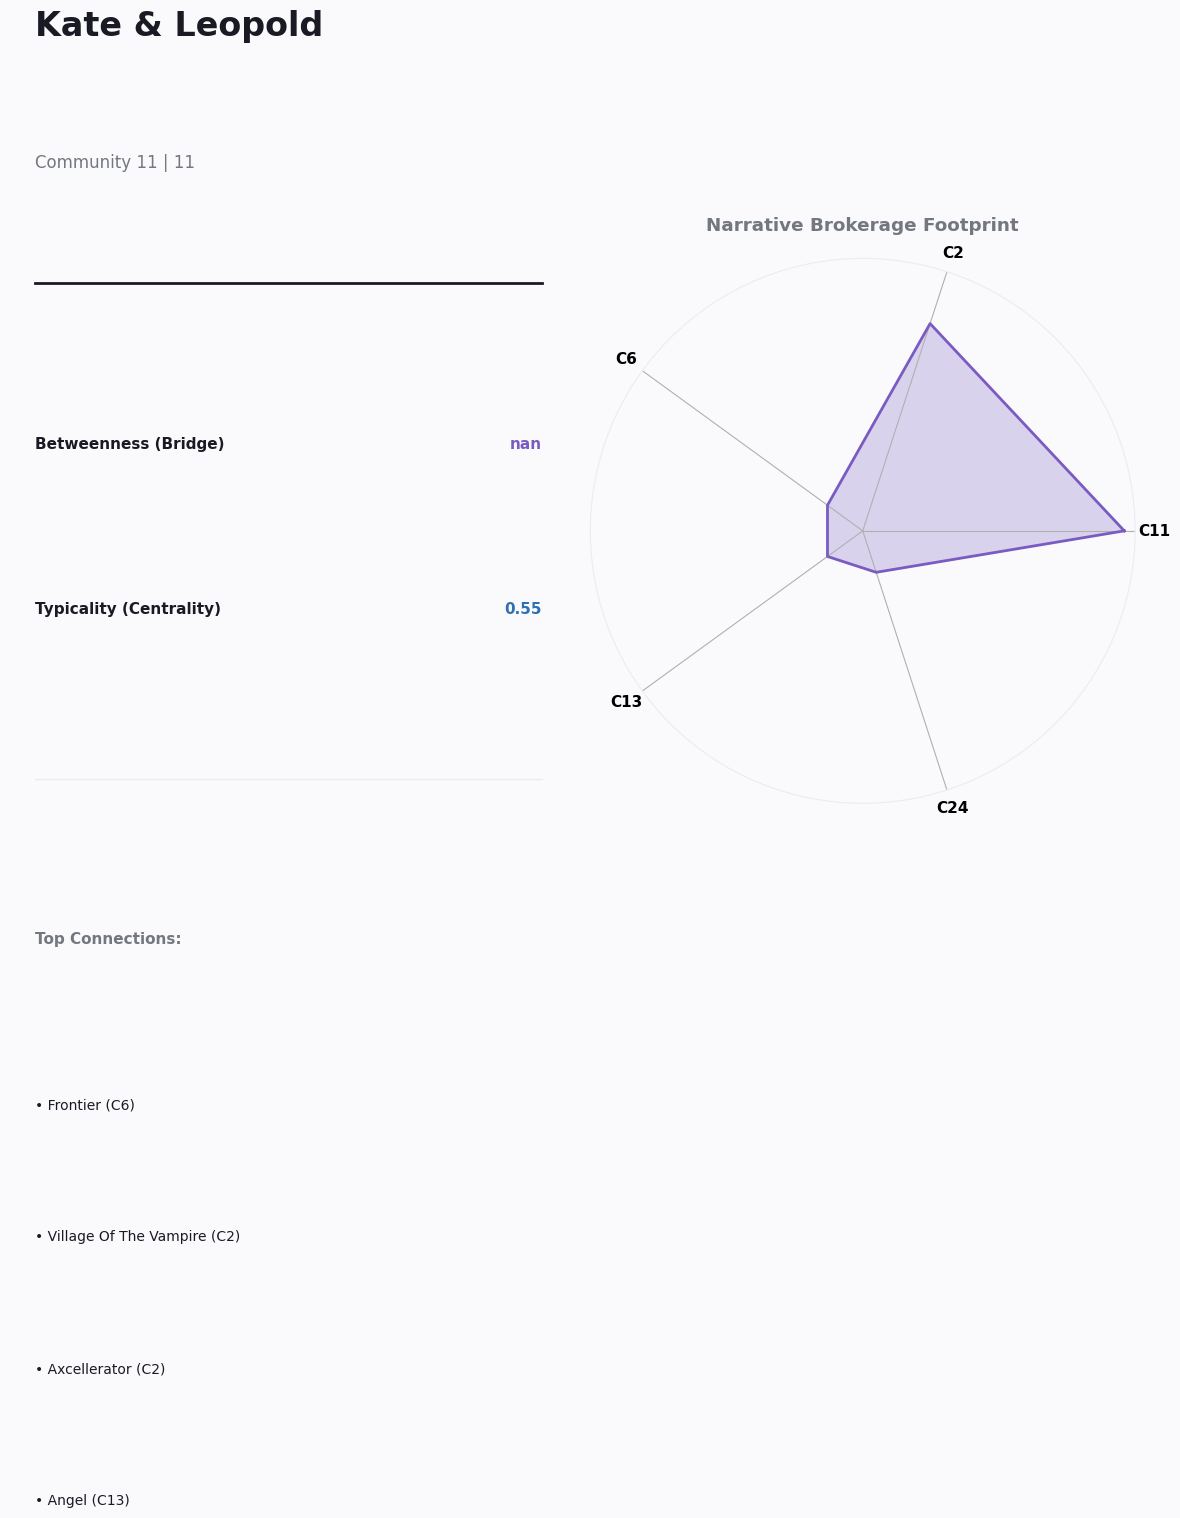

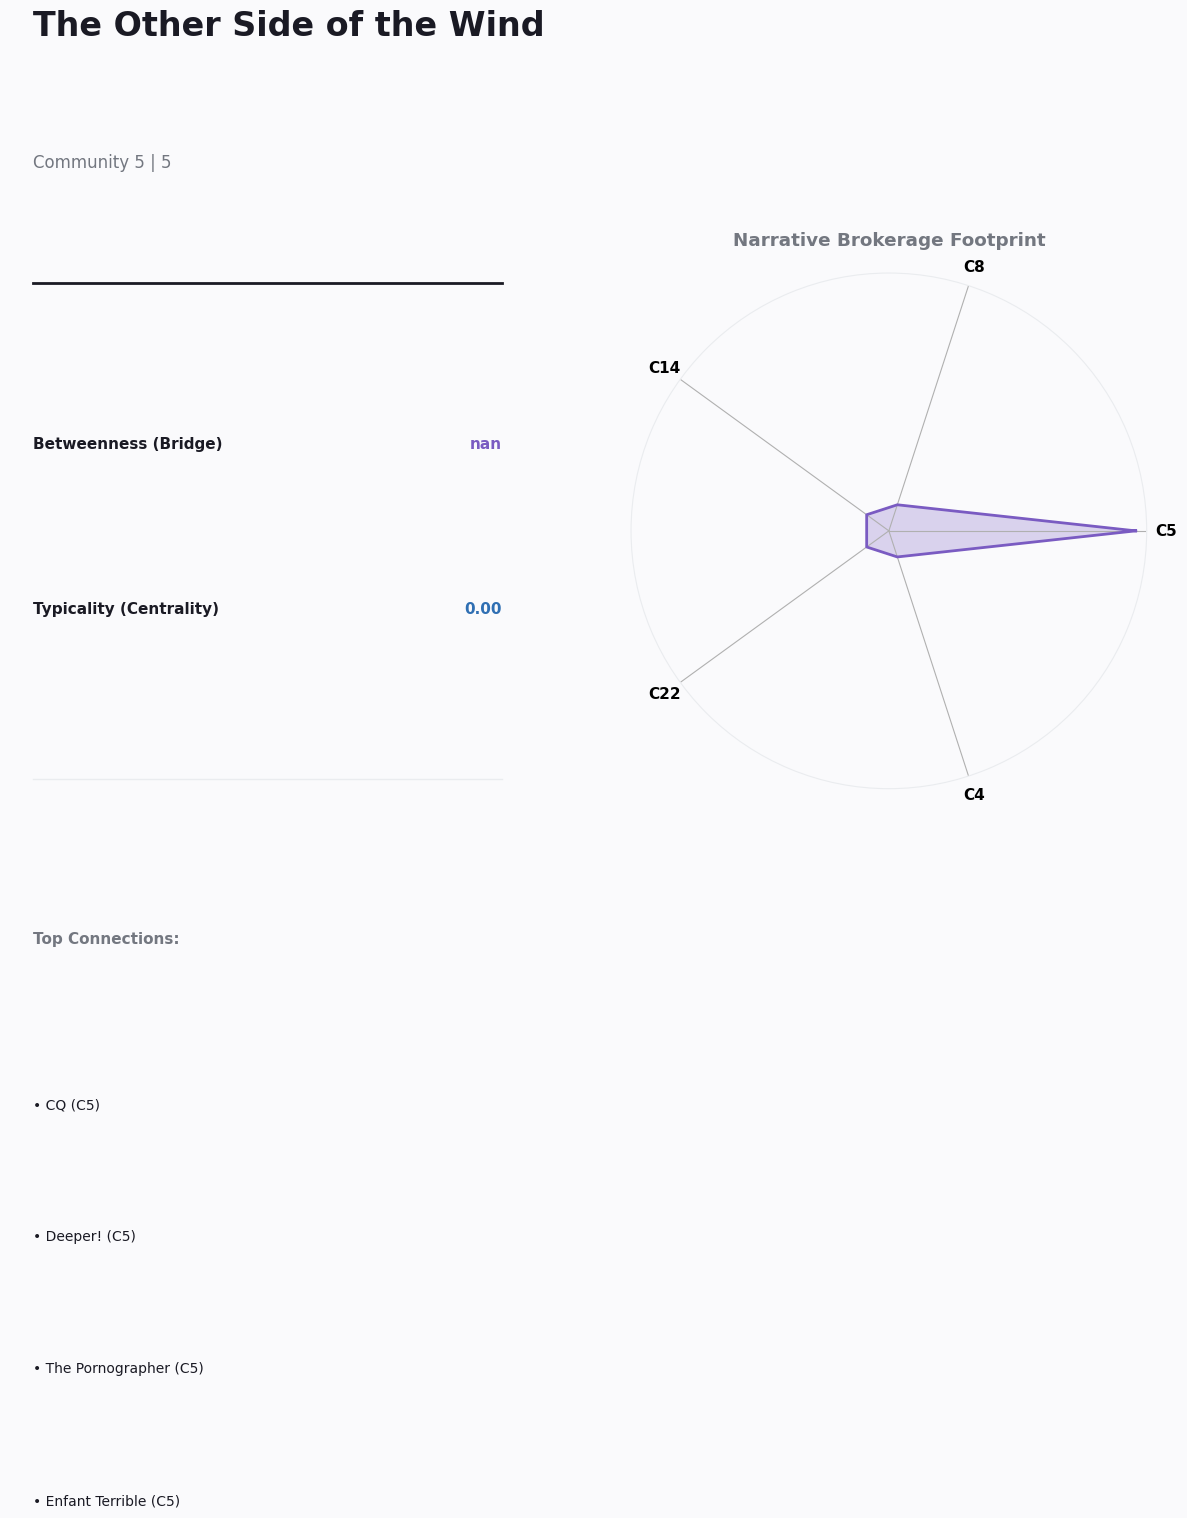

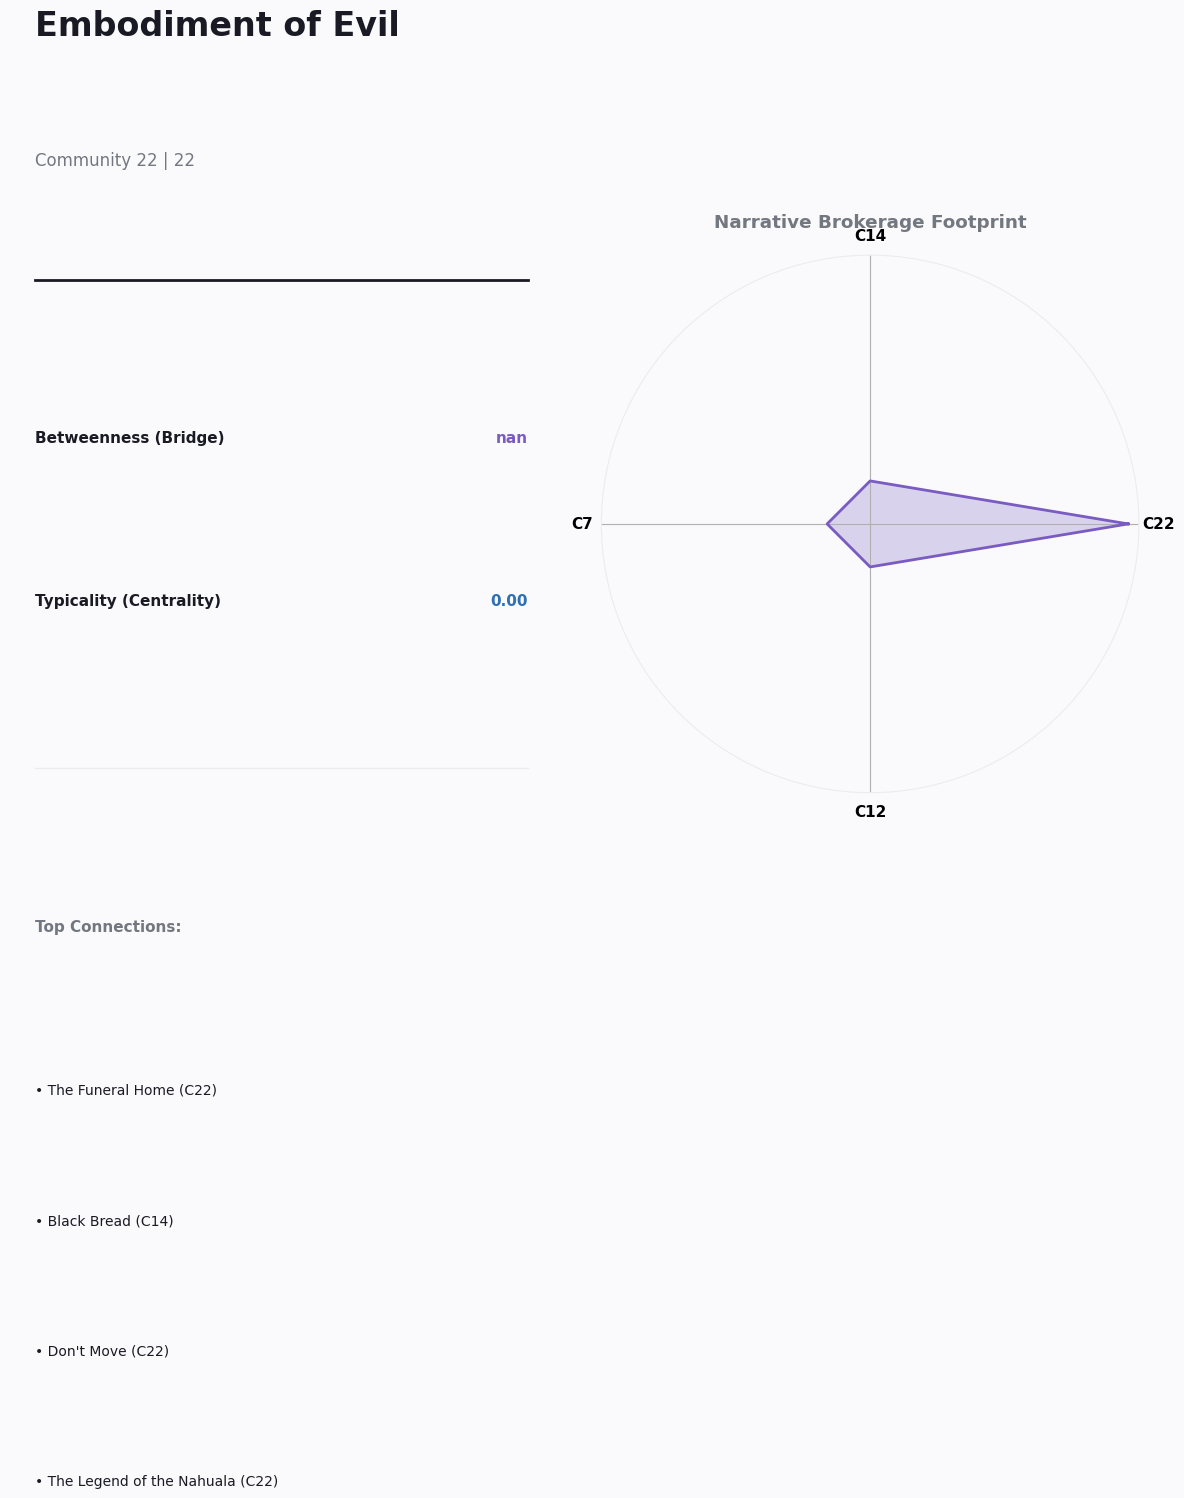

In [13]:
print("Generating Radar Profiles...")

# Ensure we have a mapping from internal node_id to the node_id_col (tmdb_id)
id_map = nodes.set_index('node_id')[node_id_col].to_dict()

# Prepare edges with mapped IDs
plot_edges = edges.copy()
plot_edges["source_id"] = plot_edges["source_node_id"].map(id_map).astype(str)
plot_edges["target_id"] = plot_edges["target_node_id"].map(id_map).astype(str)

for i, film in top_bridges.head(3).iterrows():
    nid = str(film[node_id_col])
    mask = (plot_edges["source_id"] == nid) | (plot_edges["target_id"] == nid)
    neigh = plot_edges[mask].copy()
    neigh["nid"] = np.where(neigh["source_id"] == nid, neigh["target_id"], neigh["source_id"])
    neigh = neigh.merge(nodes, left_on="nid", right_on=node_id_col)

    if neigh.empty:
        continue

    # Calculate community exposure
    dist = neigh["community_id"].value_counts(normalize=True).head(5)
    categories = [f"C{int(c)}" for c in dist.index]
    values = dist.values.tolist()

    # Close the radar circle
    categories += [categories[0]]
    values += [values[0]]
    angles = np.linspace(0, 2 * np.pi, len(categories))

    fig = plt.figure(figsize=(12, 6))
    ax_text = plt.subplot(121)
    ax_radar = plt.subplot(122, polar=True)

    # Text Panel (Clean Editorial Style)
    ax_text.axis("off")
    ax_text.text(0, 0.9, film["title"], fontsize=24, fontweight="bold")
    ax_text.text(0, 0.82, f"Community {int(film['community_id'])} | {film['label']}", fontsize=12, color=COL["muted"])

    ax_text.plot([0, 0.9], [0.75, 0.75], color=COL["ink"], lw=2)

    ax_text.text(0, 0.65, "Betweenness (Bridge)", fontweight="bold")
    ax_text.text(0.9, 0.65, f"{film['bet_norm']:.2f}", ha="right", color=COL["purple"], fontweight="bold")

    ax_text.text(0, 0.55, "Typicality (Centrality)", fontweight="bold")
    ax_text.text(0.9, 0.55, f"{film['typ_norm']:.2f}", ha="right", color=COL["blue"], fontweight="bold")

    ax_text.plot([0, 0.9], [0.45, 0.45], color=COL["grid"], lw=1)
    ax_text.text(0, 0.35, "Top Connections:", fontweight="bold", color=COL["muted"])

    y_start = 0.25
    # Use weight_x because of the merge suffix
    for _, n in neigh.nlargest(4, "weight_x").iterrows():
        ax_text.text(0, y_start, f"• {textwrap.shorten(n['title'], 40)} (C{int(n['community_id'])})", fontsize=10)
        y_start -= 0.08

    # Radar Panel
    ax_radar.plot(angles, values, color=COL["purple"], linewidth=2)
    ax_radar.fill(angles, values, color=COL["purple"], alpha=0.25)
    ax_radar.set_xticks(angles[:-1])
    ax_radar.set_xticklabels(categories[:-1], fontweight="bold")
    ax_radar.set_yticks([])
    ax_radar.spines["polar"].set_color(COL["grid"])
    ax_radar.set_title("Narrative Brokerage Footprint", pad=20, fontweight="bold", color=COL["muted"])

    plt.tight_layout()
    fig.savefig(FINAL_DIR / f"figures/05_radar_profile_{i}.png", dpi=320, bbox_inches="tight")
    plt.show()

## 4. The Stacked Brokerage Horizon (Replaces Summary Cards)

Generating Brokerage Horizons...


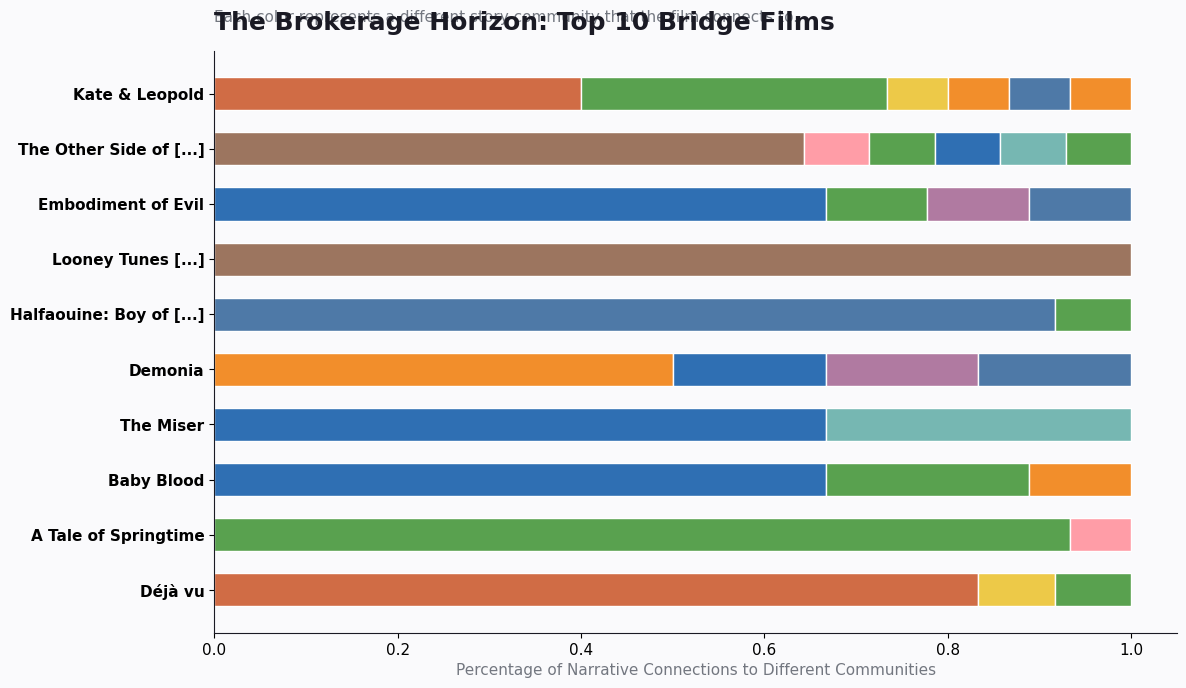

In [14]:
print("Generating Brokerage Horizons...")

# Ensure we have a mapping from internal node_id to the node_id_col (tmdb_id)
id_map = nodes.set_index('node_id')[node_id_col].to_dict()

# Prepare edges with mapped IDs
plot_edges = edges.copy()
plot_edges["source_id"] = plot_edges["source_node_id"].map(id_map).astype(str)
plot_edges["target_id"] = plot_edges["target_node_id"].map(id_map).astype(str)

fig, ax = plt.subplots(figsize=(12, 7))

y_pos = np.arange(10)
names = []

# Select top 10 bridges
horizon_targets = top_bridges.head(10)

for i, (idx, film) in enumerate(horizon_targets.iterrows()):
    names.append(textwrap.shorten(film["title"], 25))

    nid = str(film[node_id_col])
    mask = (plot_edges["source_id"] == nid) | (plot_edges["target_id"] == nid)
    neigh = plot_edges[mask].copy()
    neigh["nid"] = np.where(neigh["source_id"] == nid, neigh["target_id"], neigh["source_id"])
    neigh = neigh.merge(nodes, left_on="nid", right_on=node_id_col)

    if neigh.empty:
        continue

    dist = neigh["community_id"].value_counts(normalize=True)

    left = 0
    for comm, val in dist.items():
        c = COMM_COLORS[int(comm) % len(COMM_COLORS)]
        ax.barh(9 - i, val, left=left, color=c, edgecolor="white", height=0.6)
        left += val

ax.set_yticks(y_pos)
ax.set_yticklabels(names[::-1], fontweight="bold")
ax.set_xlabel("Percentage of Narrative Connections to Different Communities")
ax.set_title("The Brokerage Horizon: Top 10 Bridge Films", fontsize=18, fontweight="bold", loc="left", pad=15)

ax.text(0, 1.05, "Each color represents a different story community that the film connects to.", transform=ax.transAxes, color=COL["muted"])

plt.tight_layout()
fig.savefig(FINAL_DIR / "figures/08_brokerage_horizons.png", dpi=320, bbox_inches="tight")
plt.show()

In [15]:
print("\nAll Advanced Analytics Rendered Successfully!")


All Advanced Analytics Rendered Successfully!
